# Task 2.1: how often does the cat qubit bit flip?

**In plain words.** A bit flip means the light jumps from one valley ($+\alpha$) to the other ($-\alpha$). At the challenge's cat size this takes seconds, while the simulation steps in nanoseconds: brute force would need about $10^{9}$ steps. But every decay rate of a master equation is one of its eigenvalues. A bit flip changes the sign of $\langle a\rangle$, so its rate is the slowest decaying eigenvalue in the "odd" block of the Liouvillian. We compute that directly with a sparse shift-invert solver, and check it with ordinary time domain fits where those are still affordable (small cats).

**Prediction before simulating.** The textbook estimate (one photon loss hops the state across) gives $\Gamma_X \propto e^{-4\alpha^2}$. A second route exists: a photon loss kicks the state out of the code space, and the two-photon confinement pulls it back into the *wrong* valley. That route scales as $e^{-2\alpha^2}$ and costs $\kappa_a^2$ instead of $\kappa_a$, so it should win for large cats, around $\alpha^2 \gtrsim 2.3$.

In [1]:
import sys
from pathlib import Path
from IPython.display import Image, display
import pandas as pd
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'research/s2').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from research.s2 import notebook_figs as F          # loads saved results/s2/*.json, draws the figures
from research.s2.notebook_figs import load, nominal, largest
import io
from contextlib import redirect_stdout
show = lambda name, w=1000: display(Image(filename=str(ROOT / 'figures/s2' / f'{name}.png'), width=w))

In [2]:
with redirect_stdout(io.StringIO()):
    F.bit_flips()

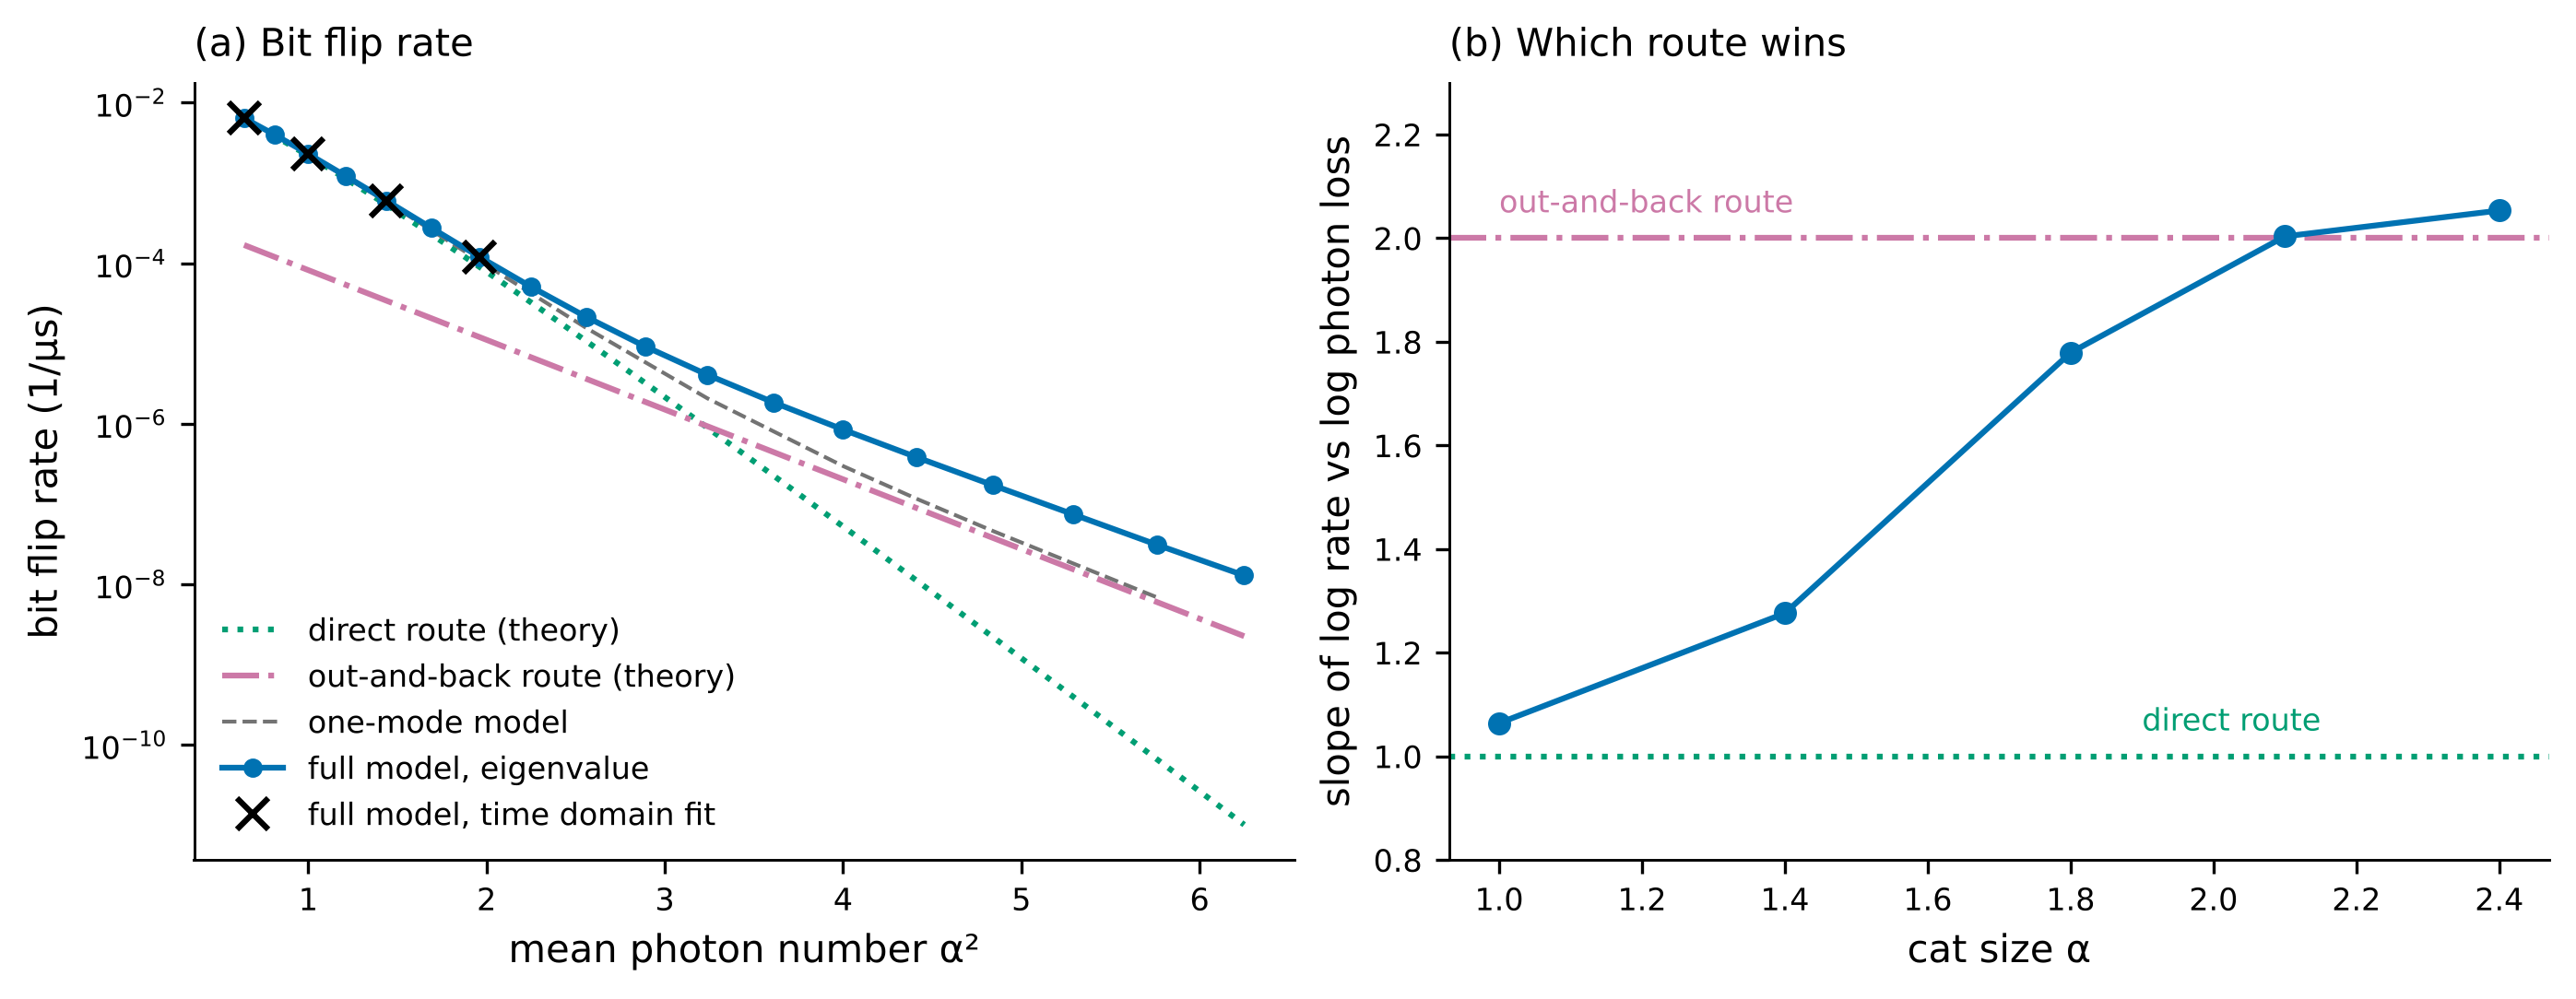

In [3]:
show('task_2_1_bit_flips')

**Bit flip rate and which escape route dominates.** (a) Bit flip rate $\Gamma_X$ against mean photon number $\alpha^2$ for the full memory + buffer model, from the slowest odd-parity Liouvillian eigenvalue (blue circles, largest truncation at each $\alpha$, curve stopped at $\alpha = 2.5$ where truncations stop agreeing). Black crosses are independent time domain fits of $\langle a\rangle(t)$ at $\alpha = 0.8$–$1.4$. The grey dashed curve is the one-mode model with the buffer adiabatically eliminated. Green dotted: direct route, $\kappa_a\alpha^2(\coth 2\alpha^2 - 1)$. Pink dash-dotted: out-and-back route, $(\kappa_a^2/\kappa_2)e^{-2\alpha^2}$. Small cats follow the direct route; large cats follow the slower-decaying out-and-back route, and the finite buffer makes the full model flip 3–4× faster still. (b) Slope of $\ln\Gamma_X$ against $\ln\kappa_a$, from sweeping $\kappa_a \times \{¼, ½, 1, 2, 4\}$ at fixed $\alpha$. A slope of 1 means one photon loss does the job (direct route); a slope of 2 means two are needed (out-and-back). The handover happens between $\alpha = 1.4$ and $2.1$, exactly where the prediction put it.

In [4]:
ALPHAS = (1.0, 1.4, 1.8, 2.1, 2.4)
best = largest(d for d in load('gx_two_*.json') if nominal(d))
pd.DataFrame([{'α': a, 'photons α²': round(a * a, 2), 'bit flip rate (1/µs)': f"{d['gamma_x']:.2e}",
               'one flip every': f"{1e-6 / d['gamma_x']:.2g} s"} for a, d in best.items() if a in ALPHAS])

,α,photons α²,bit flip rate (1/µs),one flip every
0,1.0,1.00,2.30e-03,0.00043 s
1,1.4,1.96,1.20e-04,0.0083 s
2,1.8,3.24,4.07e-06,0.25 s
3,2.1,4.41,3.85e-07,2.6 s
4,2.4,5.76,3.12e-08,32 s


**Result.** About **one bit flip every 2.6 s** at the challenge's $\alpha = 2.1$. The rate falls exponentially with cat size, but the exponent drifts from about 4 to below 2 as the dominant route changes. Fitting a single $e^{-\gamma\alpha^2}$ over the whole range would give $\gamma = 2.3$ and hide this.

## Numerical diagnostics

Each rate at its two largest truncations (memory × buffer levels). Everything plotted changes by less than 1.5%. At $\alpha = 2.6$ the truncations disagree by about 20%, which is why the curve stops at 2.5. The eigenvalue and the time domain fits agree to $2\times10^{-8}$ relative where both exist ([TECHNICAL.md](../docs/TECHNICAL.md), Task 2.1).

In [5]:
def two_largest(rows, key):
    by = {}
    for d in rows:
        by.setdefault(round(d['alpha'], 2), []).append(d)
    out = []
    for a, ds in sorted(by.items()):
        ds = sorted(ds, key=lambda d: d['na'] * d['nb'])
        if len(ds) >= 2 and a in ALPHAS:
            lo, hi = ds[-2], ds[-1]
            out.append({'α': a, 'previous size': f"{lo['na']}×{lo['nb']}", 'largest size': f"{hi['na']}×{hi['nb']}",
                        'rate (largest)': f"{hi[key]:.3e}", 'change': f"{abs(hi[key] / lo[key] - 1):.1%}"})
    return pd.DataFrame(out)

In [6]:
two_largest([d for d in load('gx_two_*.json') if nominal(d)], 'gamma_x')

,α,previous size,largest size,rate (largest),change
0,1.0,24×8,20×10,2.301e-03,0.0%
1,1.4,22×10,22×12,1.202e-04,0.0%
2,1.8,30×8,26×10,4.067e-06,0.1%
3,2.1,28×10,28×12,3.849e-07,0.1%
4,2.4,36×8,32×10,3.115e-08,1.3%
